In [1]:
#@title Header
from IPython.display import HTML, display
display(HTML("""
<div style="background:#1F2A44;color:#fff;padding:34px 40px;font-family:system-ui,-apple-system,'Segoe UI',Roboto,sans-serif;">
  <div style="font-size:30px;font-weight:650;letter-spacing:-0.01em;line-height:1.2;">Superstore Sales Performance</div>
  <div style="font-size:15.5px;margin-top:10px;color:#C9D2E3;max-width:640px;line-height:1.5;">
    Customer purchase volume, monthly seasonality, category revenue and discount sensitivity across four years of orders (2015 to 2018).
  </div>
</div>
"""))

This notebook starts from the raw order file, cleans it, and works through four questions in turn: who buys and how often, when sales peak, which categories and regions make money, and how discounting affects profit. Each section ends with a short reading of the chart, and the findings are collected at the end.

**Tools:** Python, Pandas, Matplotlib, Seaborn
**Data:** `superstore_sales.csv`, one row per order line

## Setup

In [2]:
#@title Plot theme and helpers
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from IPython.display import HTML, display

warnings.filterwarnings("ignore")

INK, MUTED, GRID = "#1F2A44", "#5B6577", "#E6EAF0"
BLUE, GREY, LOSS = "#2F5D8C", "#BAC2CE", "#B5473A"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10.5, "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GREY, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format

def short_usd(x, _=None):
    sign = "-" if x < 0 else ""
    x = abs(x)
    if x >= 1e6: return f"{sign}${x/1e6:.1f}M"
    if x >= 1e3: return f"{sign}${x/1e3:.0f}K"
    return f"{sign}${x:.0f}"

usd_axis = mtick.FuncFormatter(short_usd)
pct_axis = mtick.PercentFormatter(1, decimals=0)

def head(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 12)
    if sub:
        ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=9.5, color=MUTED, va="bottom")

def show(frame, **fmt):
    """Render a table with a light header and formatted columns."""
    styled = (frame.style.format(fmt)
              .set_table_styles([
                  {"selector": "th", "props": [("text-align", "right"), ("font-weight", "600"),
                                               ("border-bottom", "1.5px solid #1F2A44")]},
                  {"selector": "th.row_heading", "props": [("text-align", "left")]},
                  {"selector": "td", "props": [("text-align", "right"), ("padding", "6px 14px")]}]))
    display(styled)

In [3]:
# Colab: pick superstore_sales.csv when prompted. Skipped outside Colab.
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

raw = pd.read_csv("superstore_sales.csv")
raw.shape

(10800, 21)

## Data cleaning

The raw file has 10,800 rows and about 800 of them are almost entirely empty. They are not missing data in the usual sense: two small lookup tables (regional managers and returned order IDs) sit below the order records in the same sheet, so they were read in as rows with only the first two columns filled.

In [4]:
raw.iloc[9990:9998, :4]

,Row ID,Order ID,Order Date,Ship Date
9990,9991,CA-2018-121258,2/26/2018,3/3/2018
9991,9992,CA-2018-121258,2/26/2018,3/3/2018
9992,9993,CA-2018-121258,2/26/2018,3/3/2018
9993,9994,CA-2018-119914,5/4/2018,5/9/2018
9994,Person,Region,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN
9996,Chuck Magee,East,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN


The order records end at row 9,994. Rows without an `Order Date` are removed, dates are parsed, and exact duplicates are checked ignoring `Row ID`, since that column is unique by construction.

In [5]:
df = raw.dropna(subset=["Order Date"]).copy()

df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

key_cols = [c for c in df.columns if c != "Row ID"]
n_dupes = df.duplicated(subset=key_cols).sum()
df = df.drop_duplicates(subset=key_cols)

# time features
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")
df["Profit Margin"] = df["Profit"] / df["Sales"]

# checks
assert df["Order Date"].between("2015-01-01", "2018-12-31").all()
assert (df["Ship Date"] >= df["Order Date"]).all()

log = pd.Series({
    "Rows in file": len(raw),
    "Non-order rows removed": len(raw) - len(df) - n_dupes,
    "Duplicate rows removed": n_dupes,
    "Order lines kept": len(df),
    "Nulls remaining (Postal Code)": int(df.isna().sum().sum()),
}, name="Rows")
log.to_frame().style.format("{:,}")

,Rows
Rows in file,"10,800"
Non-order rows removed,806
Duplicate rows removed,1
Order lines kept,"9,993"
Nulls remaining (Postal Code),11


The only remaining nulls are the `Postal Code` values for Burlington, Vermont. Postal code is not used in this analysis, so they stay as they are.

## Headline numbers

In [6]:
#@title Headline figures
yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
yearly["Sales growth"] = yearly["Sales"].pct_change()

total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
kpis = [
    ("Sales", short_usd(total_sales)),
    ("Profit", short_usd(total_profit)),
    ("Profit margin", f"{total_profit / total_sales:.1%}"),
    ("Orders", f"{df['Order ID'].nunique():,}"),
    ("Customers", f"{df['Customer ID'].nunique():,}"),
]
cells = "".join(
    f"""<div style="flex:1;padding:4px 22px;border-left:1px solid #CBD2DE;">
          <div style="font-size:13px;color:#5B6577;">{label}</div>
          <div style="font-size:28px;font-weight:650;color:#1F2A44;margin-top:2px;">{value}</div>
        </div>""" for label, value in kpis)
display(HTML(f"""<div style="display:flex;flex-wrap:wrap;gap:14px 0;background:#F3F5F8;padding:20px 12px;
  font-family:system-ui,-apple-system,'Segoe UI',Roboto,sans-serif;">{cells}</div>"""))

In [7]:
show(yearly, Sales="${:,.0f}", Profit="${:,.0f}", Margin="{:.1%}", **{"Sales growth": "{:+.1%}"})

,Sales,Profit,Margin,Sales growth
Year,,,,
2015,"$483,966","$49,556",10.2%,+nan%
2016,"$470,533","$61,619",13.1%,-2.8%
2017,"$609,206","$81,795",13.4%,+29.5%
2018,"$733,215","$93,439",12.7%,+20.4%


## Revenue and profit by category, region and segment

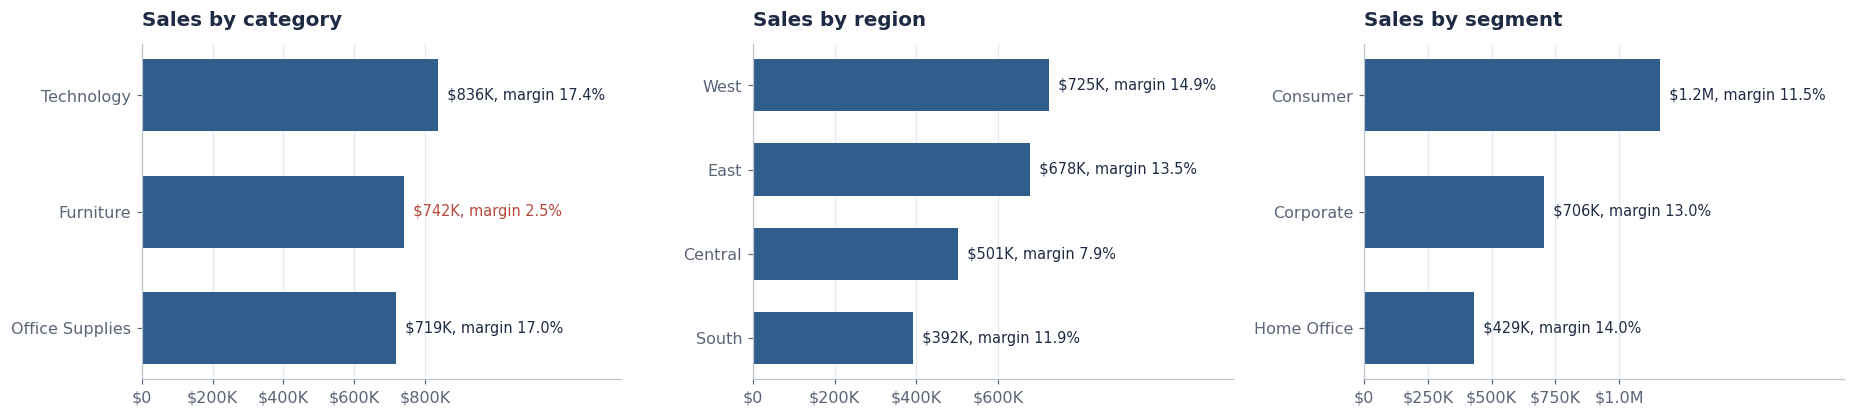

In [8]:
def summarize(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                           Orders=("Order ID", "nunique"))
    g["Margin"] = g["Profit"] / g["Sales"]
    g["Share of sales"] = g["Sales"] / g["Sales"].sum()
    return g.sort_values("Sales", ascending=False)

def sales_bars(ax, by, title):
    g = summarize(by).sort_values("Sales")
    ax.barh(g.index, g["Sales"], color=BLUE, height=0.62)
    for i, (sales, margin) in enumerate(zip(g["Sales"], g["Margin"])):
        flag = LOSS if margin < 0.05 else INK          # margin under 5% shown in red
        ax.text(sales, i, f"  {short_usd(sales)}, margin {margin:.1%}", va="center",
                fontsize=9.5, color=flag)
    ax.set_xlim(0, g["Sales"].max() * 1.62)
    ax.set_xticks([t for t in ax.get_xticks() if t <= g["Sales"].max() * 1.02])
    ax.xaxis.set_major_formatter(usd_axis)
    ax.grid(axis="y", visible=False)
    head(ax, title)

fig, axes = plt.subplots(1, 3, figsize=(17, 3.9))
for ax, by in zip(axes, ["Category", "Region", "Segment"]):
    sales_bars(ax, by, f"Sales by {by.lower()}")
plt.tight_layout()
plt.show()

In [9]:
show(summarize("Category"), Sales="${:,.0f}", Profit="${:,.0f}", Orders="{:,}",
     Margin="{:.1%}", **{"Share of sales": "{:.1%}"})

,Sales,Profit,Orders,Margin,Share of sales
Category,,,,,
Technology,"$836,154","$145,455","1,544",17.4%,36.4%
Furniture,"$741,718","$18,463","1,764",2.5%,32.3%
Office Supplies,"$719,047","$122,491","3,742",17.0%,31.3%


**Reading the charts.** Technology leads on sales ($836K) and margin (17.4%). Furniture is nearly level with Office Supplies on revenue but earns a margin of only 2.5%. West and East together bring in 61% of sales; Central has the lowest margin of the four regions. By segment, Consumer is half of all revenue, while Home Office has the best margin.

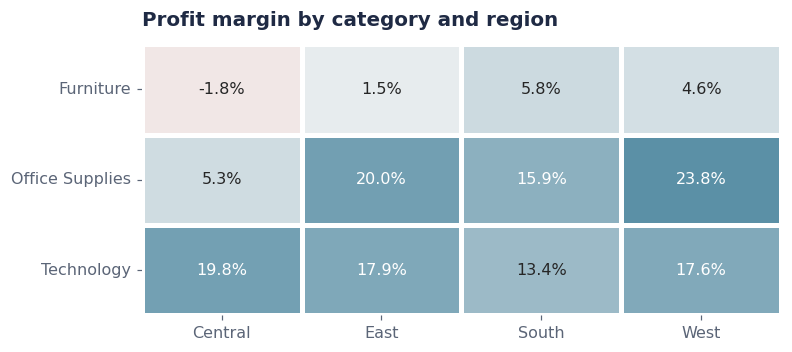

In [10]:
margin_grid = (df.groupby(["Category", "Region"])
                 .apply(lambda x: x["Profit"].sum() / x["Sales"].sum())
                 .unstack())

fig, ax = plt.subplots(figsize=(7.5, 3.2))
sns.heatmap(margin_grid, annot=True, fmt=".1%", cmap=sns.diverging_palette(15, 225, s=65, l=55, as_cmap=True),
            center=0, vmin=-0.25, vmax=0.25, cbar=False, linewidths=2, linecolor="white",
            annot_kws={"size": 10.5}, ax=ax)
ax.grid(False)
ax.set_xlabel(""); ax.set_ylabel("")
head(ax, "Profit margin by category and region")
plt.show()

Furniture in Central is the only combination that loses money overall (-1.8%). Office Supplies in the West (23.8%) and East (20.0%) are the strongest.

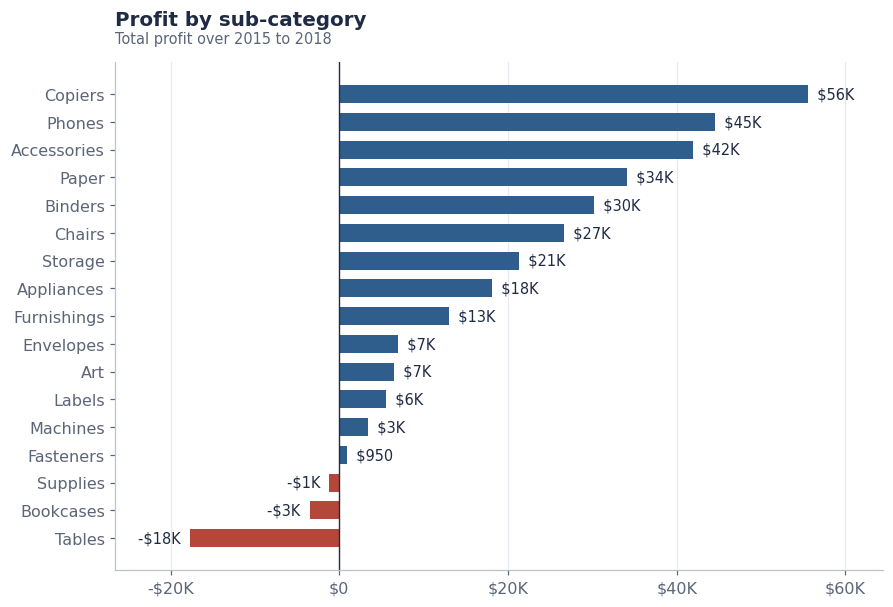

In [11]:
sub = summarize("Sub-Category").sort_values("Profit")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sub.index, sub["Profit"], color=[LOSS if p < 0 else BLUE for p in sub["Profit"]], height=0.65)
for i, p in enumerate(sub["Profit"]):
    ax.text(p, i, f"  {short_usd(p)}  " if p >= 0 else f"{short_usd(p)}  ",
            va="center", ha="left" if p >= 0 else "right", fontsize=9.5)
ax.axvline(0, color=INK, lw=0.9)
ax.xaxis.set_major_formatter(usd_axis)
ax.grid(axis="y", visible=False)
ax.margins(x=0.12)
head(ax, "Profit by sub-category", "Total profit over 2015 to 2018")
plt.show()

Tables (-$17.7K), Bookcases (-$3.5K) and Supplies (-$1.2K) are the three sub-categories that lose money. Copiers, Accessories and Phones lead in absolute profit.

## Monthly sales and seasonality

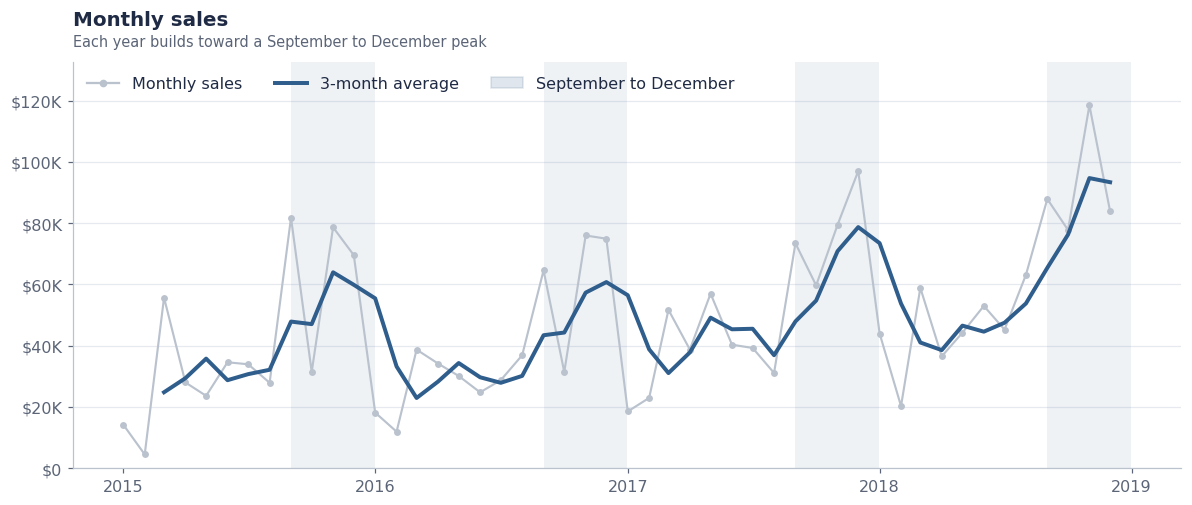

In [12]:
monthly = df.groupby("Year-Month")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4.8))
for y in range(2015, 2019):
    ax.axvspan(pd.Timestamp(y, 9, 1), pd.Timestamp(y, 12, 31), color=BLUE, alpha=0.08, lw=0)
ax.plot(monthly.index, monthly.values, color=GREY, lw=1.4, marker="o", ms=3.5)
ax.plot(monthly.index, monthly.rolling(3).mean(), color=BLUE, lw=2.6)
ax.yaxis.set_major_formatter(usd_axis)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Line2D([], [], color=GREY, marker="o", ms=4, label="Monthly sales"),
                   plt.Line2D([], [], color=BLUE, lw=2.6, label="3-month average"),
                   Patch(color=BLUE, alpha=0.15, label="September to December")],
          loc="upper left", ncol=3)
ax.set_ylim(0, monthly.max() * 1.12)
head(ax, "Monthly sales", "Each year builds toward a September to December peak")
plt.show()

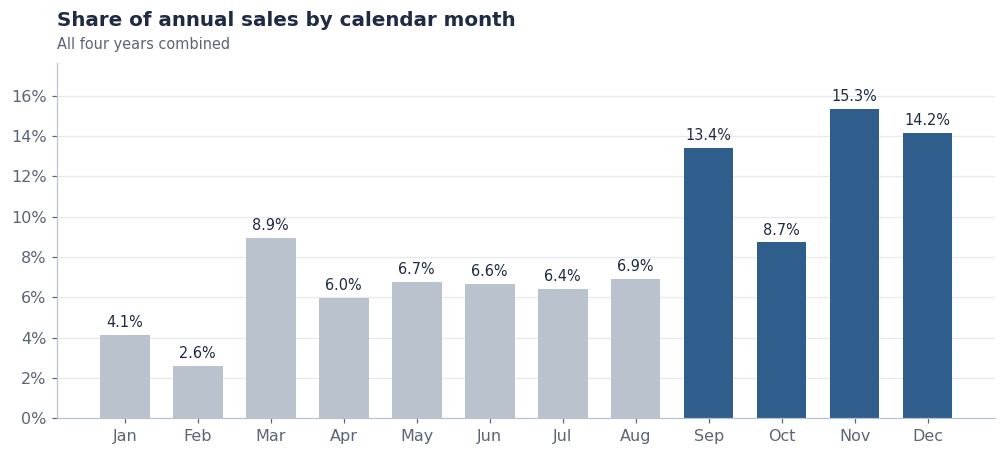

September to December: 51.6% of sales
November and December: 29.5%
January and February:  6.7%


In [13]:
by_month = df.groupby("Month")["Sales"].sum()
share = by_month / by_month.sum()
names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(names, share.values, color=[BLUE if m >= 9 else GREY for m in share.index], width=0.68)
for i, v in enumerate(share.values):
    ax.text(i, v + 0.004, f"{v:.1%}", ha="center", fontsize=9.5)
ax.yaxis.set_major_formatter(pct_axis)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, share.max() * 1.15)
head(ax, "Share of annual sales by calendar month", "All four years combined")
plt.show()

print(f"September to December: {share.loc[9:12].sum():.1%} of sales")
print(f"November and December: {share.loc[11:12].sum():.1%}")
print(f"January and February:  {share.loc[1:2].sum():.1%}")

Sales climb every autumn: September to December delivers 51.6% of annual revenue, and November and December alone deliver 29.5%. January and February together are under 7%. The same shape holds in each of the four years, so the pattern is structural rather than a one-off.

## Customer purchase volume

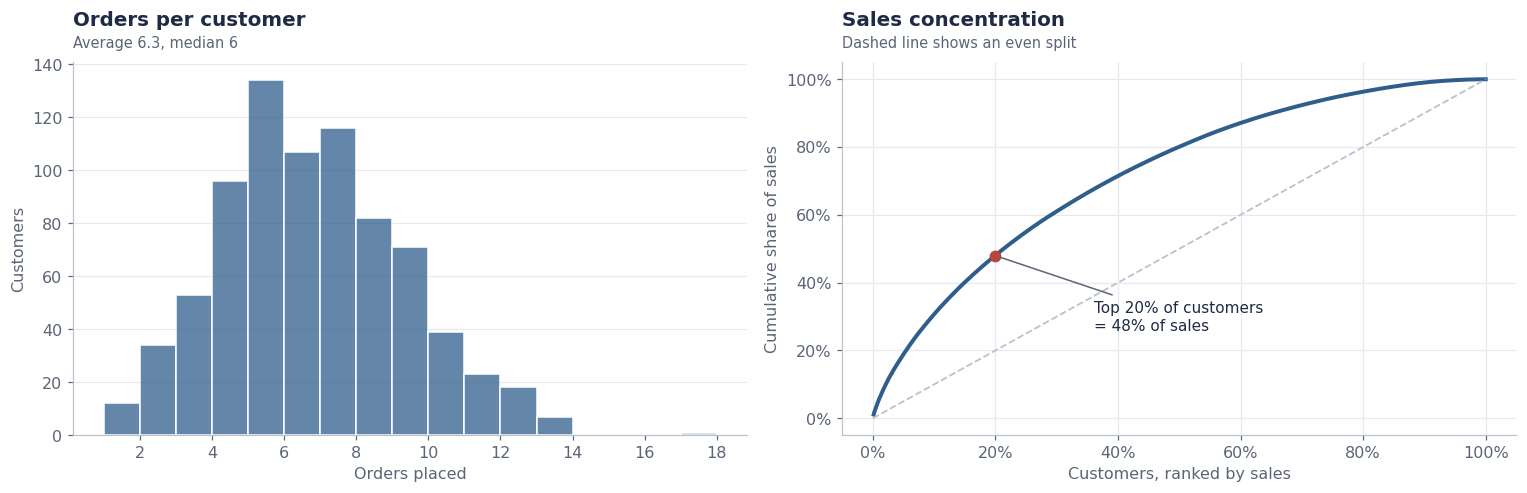

In [14]:
cust = (df.groupby("Customer ID")
          .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
          .sort_values("Sales", ascending=False))

top_n = int(len(cust) * 0.2)
top_share = cust["Sales"].head(top_n).sum() / cust["Sales"].sum()
repeat_rate = (cust["Orders"] >= 2).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

sns.histplot(cust["Orders"], bins=range(1, 19), color=BLUE, edgecolor="white", ax=axes[0])
axes[0].grid(axis="x", visible=False)
axes[0].xaxis.set_major_locator(mtick.MultipleLocator(2))
axes[0].set_xlabel("Orders placed"); axes[0].set_ylabel("Customers")
head(axes[0], "Orders per customer", f"Average {cust['Orders'].mean():.1f}, median {cust['Orders'].median():.0f}")

cum = cust["Sales"].cumsum() / cust["Sales"].sum()
x = np.arange(1, len(cum) + 1) / len(cum)
axes[1].plot(x, cum.values, color=BLUE, lw=2.6)
axes[1].plot([0, 1], [0, 1], color=GREY, lw=1.2, ls="--")
axes[1].scatter([0.2], [top_share], color=LOSS, zorder=3, s=45)
axes[1].annotate(f"Top 20% of customers\n= {top_share:.0%} of sales", (0.2, top_share),
                 xytext=(0.36, top_share - 0.22), fontsize=10,
                 arrowprops=dict(arrowstyle="-", color=MUTED, shrinkA=6, shrinkB=4))
axes[1].xaxis.set_major_formatter(pct_axis); axes[1].yaxis.set_major_formatter(pct_axis)
axes[1].set_xlabel("Customers, ranked by sales"); axes[1].set_ylabel("Cumulative share of sales")
head(axes[1], "Sales concentration", "Dashed line shows an even split")
plt.tight_layout()
plt.show()

There are 793 customers and 5,009 orders. Almost every customer buys more than once (98.5%), so the base is repeat buyers rather than one-time shoppers. The top fifth of customers account for 48% of sales.

## Discount sensitivity

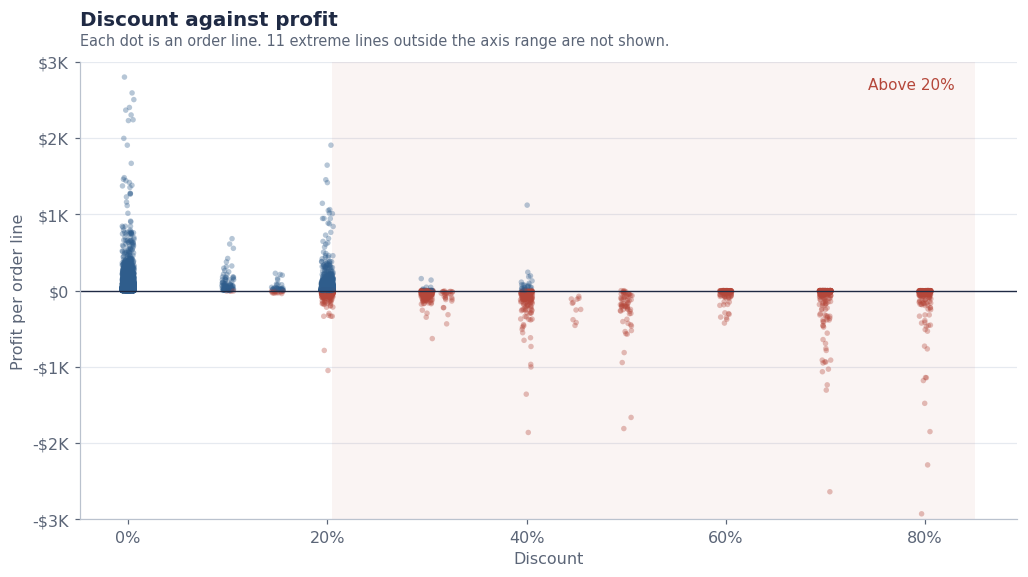

Correlation, discount vs profit:        -0.22
Correlation, discount vs profit margin: -0.86


In [15]:
rng = np.random.default_rng(7)
y_lo, y_hi = -3000, 3000
inside = df["Profit"].between(y_lo, y_hi)
d = df[inside]
jitter = rng.uniform(-0.006, 0.006, len(d))

fig, ax = plt.subplots(figsize=(11, 5.4))
ax.axvspan(0.205, 0.85, color=LOSS, alpha=0.06, lw=0)
ax.scatter(d["Discount"] + jitter, d["Profit"], s=13, alpha=0.35, lw=0,
           c=np.where(d["Profit"] < 0, LOSS, BLUE))
ax.axhline(0, color=INK, lw=0.9)
ax.grid(axis="x", visible=False)
ax.set_ylim(y_lo, y_hi)
ax.xaxis.set_major_formatter(pct_axis); ax.yaxis.set_major_formatter(usd_axis)
ax.set_xlabel("Discount"); ax.set_ylabel("Profit per order line")
ax.text(0.83, y_hi * 0.88, "Above 20%", ha="right", color=LOSS, fontsize=10)
head(ax, "Discount against profit",
     f"Each dot is an order line. {(~inside).sum()} extreme lines outside the axis range are not shown.")
plt.show()

print(f"Correlation, discount vs profit:        {df['Discount'].corr(df['Profit']):.2f}")
print(f"Correlation, discount vs profit margin: {df['Discount'].corr(df['Profit Margin']):.2f}")

,Lines,Sales,Profit,Margin
Discount,,,,
None,"4,798","$1,087,908","$320,988",29.5%
Up to 10%,94,"$54,369","$9,029",16.6%
10-20%,"3,709","$792,153","$91,756",11.6%
20-30%,226,"$102,945","$-10,357",-10.1%
30-40%,233,"$130,911","$-25,448",-19.4%
40-50%,77,"$64,404","$-23,000",-35.7%
Over 50%,856,"$64,229","$-76,559",-119.2%


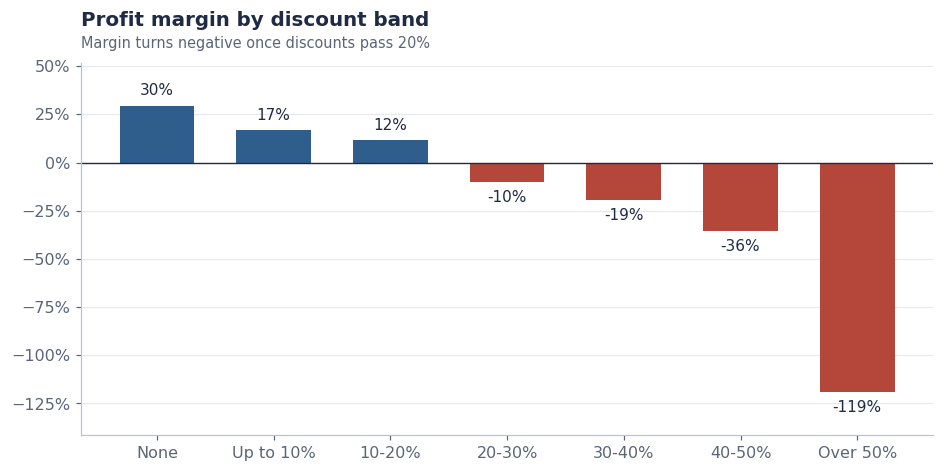

In [16]:
bands = pd.cut(df["Discount"], [-0.01, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 1],
               labels=["None", "Up to 10%", "10-20%", "20-30%", "30-40%", "40-50%", "Over 50%"])
band = (df.groupby(bands, observed=True)
          .agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum")))
band["Margin"] = band["Profit"] / band["Sales"]
band.index.name = "Discount"
show(band, Lines="{:,}", Sales="${:,.0f}", Profit="${:,.0f}", Margin="{:.1%}")

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(band.index.astype(str), band["Margin"], color=[LOSS if m < 0 else BLUE for m in band["Margin"]], width=0.64)
for i, m in enumerate(band["Margin"]):
    ax.text(i, m + (0.04 if m >= 0 else -0.04), f"{m:.0%}", ha="center", va="bottom" if m >= 0 else "top", fontsize=10)
ax.axhline(0, color=INK, lw=0.9)
ax.yaxis.set_major_formatter(pct_axis)
ax.grid(axis="x", visible=False)
ax.margins(y=0.15)
head(ax, "Profit margin by discount band", "Margin turns negative once discounts pass 20%")
plt.show()

In [17]:
loss = df[df["Profit"] < 0]
heavy_share_of_loss = (loss["Discount"] > 0.2).mean()
print(f"Loss-making lines: {len(loss) / len(df):.1%} of all lines, ${-loss['Profit'].sum():,.0f} in total losses")
print(f"{heavy_share_of_loss:.0%} of those lines carry a discount above 20%\n")

region_disc = (df.groupby("Region").agg(**{"Average discount": ("Discount", "mean")})
                 .join(summarize("Region")["Margin"]).sort_values("Average discount", ascending=False))
show(region_disc, **{"Average discount": "{:.1%}", "Margin": "{:.1%}"})

heavy = (df.assign(heavy=df["Discount"] > 0.2).groupby("Sub-Category")["heavy"].mean()
           .sort_values(ascending=False).head(5).to_frame("Lines discounted over 20%"))
show(heavy, **{"Lines discounted over 20%": "{:.0%}"})

Loss-making lines: 18.7% of all lines, $156,119 in total losses
72% of those lines carry a discount above 20%



,Average discount,Margin
Region,,
Central,24.0%,7.9%
South,14.7%,11.9%
East,14.5%,13.5%
West,10.9%,14.9%


,Lines discounted over 20%
Sub-Category,
Tables,55%
Machines,46%
Binders,40%
Bookcases,31%
Chairs,25%


Profit falls steadily as the discount rises. Undiscounted lines earn a 29.5% margin, lines at 10-20% earn 11.6%, and every band above 20% loses money. Central gives the deepest average discount (24%, against 11% in the West) and has the lowest margin as a result. Tables, Machines and Binders are the sub-categories most often sold at deep discounts.

## Findings

In [18]:
#@title Findings
band_m = band["Margin"]
cat = summarize("Category"); reg = summarize("Region")
t_sub = summarize("Sub-Category")
core_profit = cat.loc[["Technology", "Office Supplies"], "Profit"].sum() / cat["Profit"].sum()
peak = share.loc[9:12].sum(); trough = share.loc[1:2].sum()

findings = [
    ("Discounts above 20% are where profit is lost",
     f"Margin is {band_m['None']:.1%} with no discount and {band_m['10-20%']:.1%} at 10-20%. Every band above 20% is negative, "
     f"and {heavy_share_of_loss:.0%} of loss-making order lines carry a discount over 20%.",
     "Cap standard discounts at 20% and require sign-off above it."),
    ("Furniture generates revenue without profit",
     f"Furniture sales of {short_usd(cat.loc['Furniture', 'Sales'])} match the other categories, but its margin is "
     f"{cat.loc['Furniture', 'Margin']:.1%} against about 17% for Technology and Office Supplies, which together produce "
     f"{core_profit:.0%} of profit. Tables lose {short_usd(-t_sub.loc['Tables', 'Profit'])} on {short_usd(t_sub.loc['Tables', 'Sales'])} of sales.",
     "Reprice or renegotiate supplier costs on Tables and Bookcases before pushing volume."),
    ("Half of annual sales arrive between September and December",
     f"{peak:.1%} of sales fall in those four months and only {trough:.1%} in January and February. The pattern repeats in every year of the data.",
     "Build inventory and staffing ahead of September, and run promotions in the slow first quarter."),
    ("A fifth of customers drive nearly half of revenue",
     f"The top 20% of customers account for {top_share:.0%} of sales, and {repeat_rate:.1%} of all customers have ordered more than once.",
     "Put retention effort into the best accounts before spending on new-customer acquisition."),
    ("Central lags the other regions and discounts more heavily",
     f"Central margin is {reg.loc['Central', 'Margin']:.1%} against {reg.loc['West', 'Margin']:.1%} in the West. Its average discount is "
     f"{df.loc[df.Region == 'Central', 'Discount'].mean():.0%}, more than double the West's {df.loc[df.Region == 'West', 'Discount'].mean():.0%}.",
     "Start the discount review in Central, where the gap to the West is widest."),
    ("Sales are growing faster than margin",
     f"Sales rose {yearly.loc[2018, 'Sales growth']:.0%} in 2018, but margin slipped from {yearly.loc[2017, 'Margin']:.1%} to {yearly.loc[2018, 'Margin']:.1%}.",
     "Track margin alongside sales so growth bought with discounts shows up early."),
]

rows = "".join(f"""
  <div style="border-left:3px solid #2F5D8C;padding:2px 0 2px 18px;margin:0 0 26px 0;">
    <div style="font-size:17px;font-weight:650;color:#1F2A44;line-height:1.3;">{i}. {title}</div>
    <div style="font-size:14.5px;color:#2B3652;margin-top:6px;line-height:1.55;max-width:760px;">{evidence}</div>
    <div style="font-size:14.5px;color:#2F5D8C;margin-top:6px;line-height:1.55;max-width:760px;"><b>Recommended:</b> {action}</div>
  </div>""" for i, (title, evidence, action) in enumerate(findings, 1))

display(HTML(f"""<div style="background:#F3F5F8;padding:30px 34px 8px 34px;
  font-family:system-ui,-apple-system,'Segoe UI',Roboto,sans-serif;">{rows}</div>"""))

**Limits of the data.** The discount relationship is a correlation. Some deep discounts may be clearance of products that were already unprofitable, so cutting them would not recover the full loss. The file has no cost, return or cancellation fields, so margin is taken as `Profit / Sales` exactly as supplied.